In [2]:
pacman::p_load(dplyr,ggplot2)

In [1]:
nerrs_metaT=read.csv("../output/metaT_informed_NERRS.csv")

In [3]:
nerrs_allometry=read.csv("../output/allometry_NERRS_same_temps.csv")

In [4]:
nerrs_merged=nerrs_metaT %>%
    dplyr::filter(index>50) %>% 
    dplyr::rename(c("metaT"="abund")) %>%
    dplyr::inner_join(nerrs_allometry%>%
                     dplyr::rename(c("allometry"="abund")),
                    by=c("DateTime","taxon","Site"))

Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


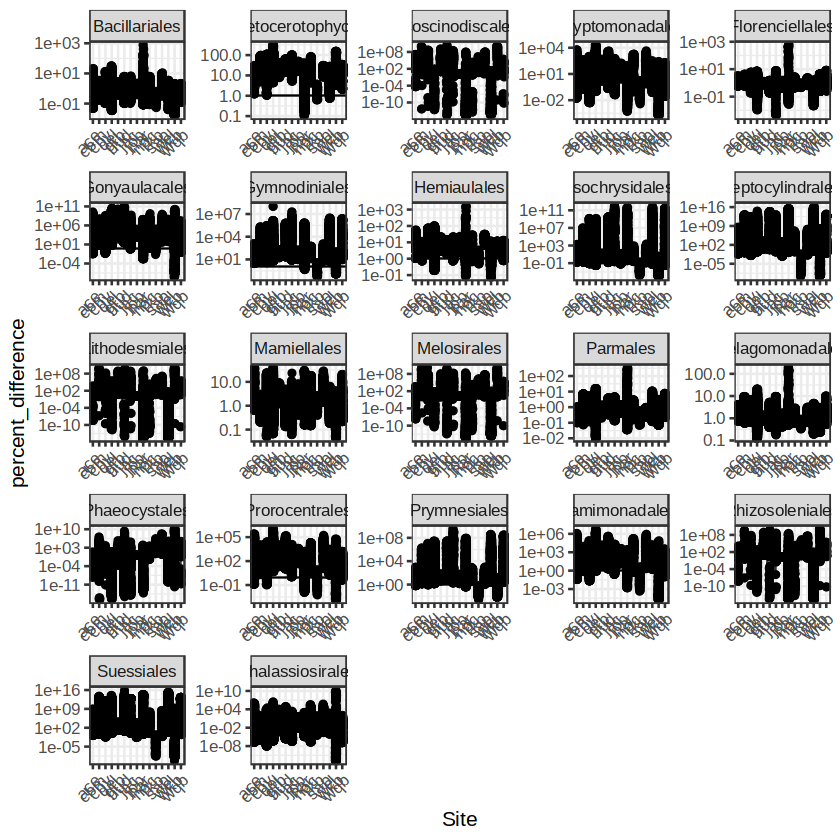

In [5]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=Site,y=percent_difference))+
    geom_jitter(aes(Site,y=percent_difference),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~taxon,scales="free") + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


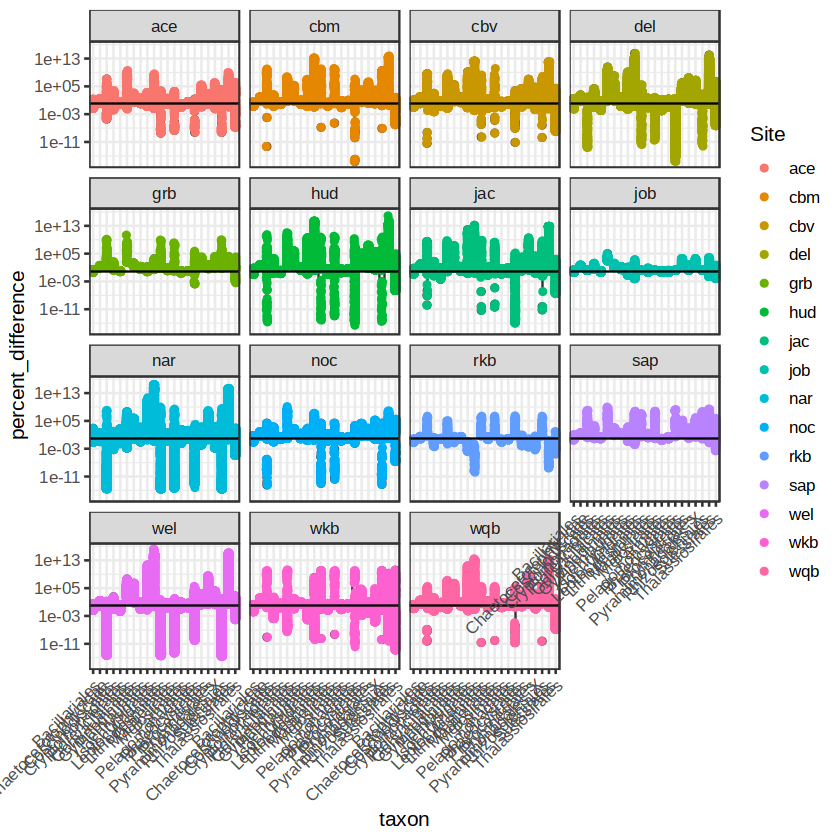

In [6]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    facet_wrap(~Site) + 
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message in transformation$transform(x):
“NaNs produced”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 58898 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 58898 rows containing missing values or values outside the scale range
(`geom_point()`).”


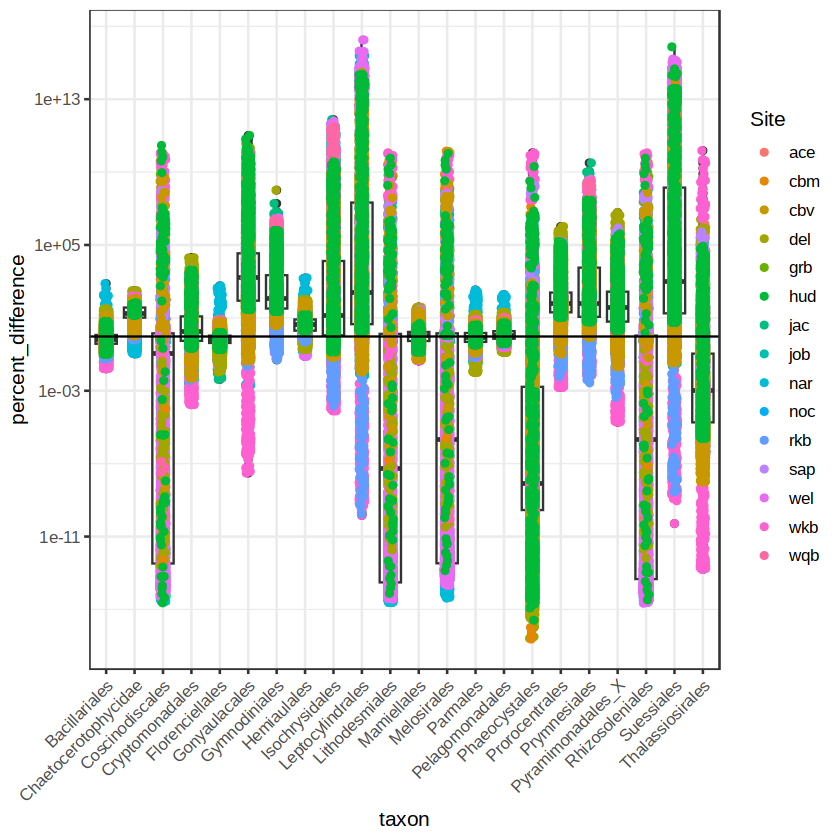

In [7]:
ggplot(nerrs_merged%>%
    dplyr::mutate(percent_difference = allometry/metaT) %>% #(allometry-abund)/(mean(allometry)+mean(abund))) %>%
    dplyr::filter(!(taxon%in%c("zoop","nitrogen","phosphorus"))))+#/((allometry+abund)/2))) + 
    geom_boxplot(aes(x=taxon,y=percent_difference))+
    geom_jitter(aes(taxon,y=percent_difference,color=Site),
               height=0,width=0.1) +
    geom_hline(aes(yintercept=1))+
    scale_y_log10() + 
    theme_bw(base_size=12)+ 
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

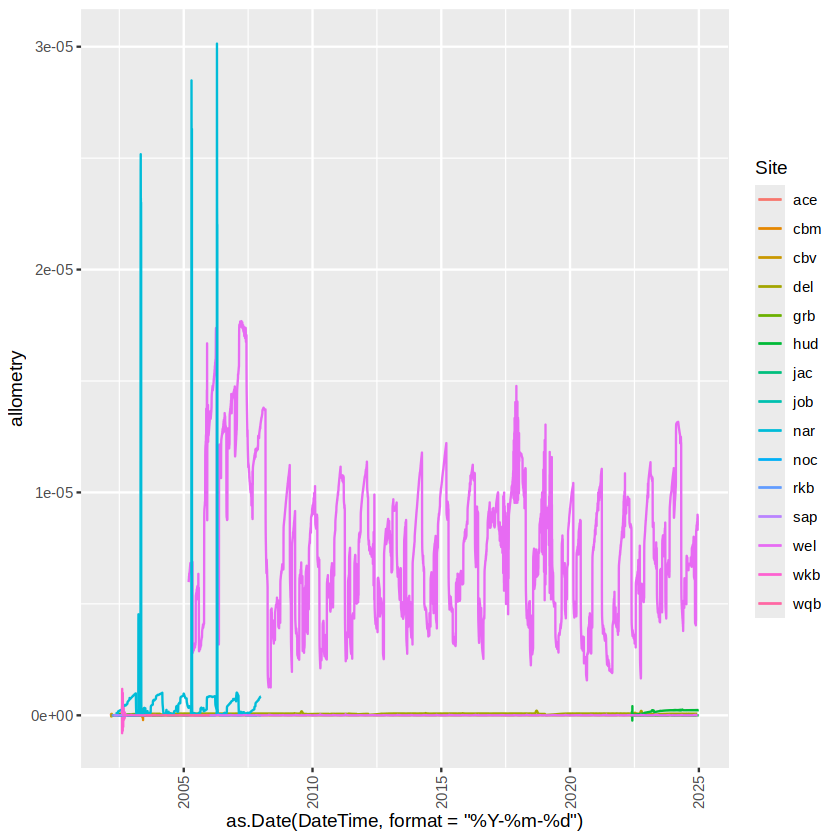

In [8]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Gonyaulacales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

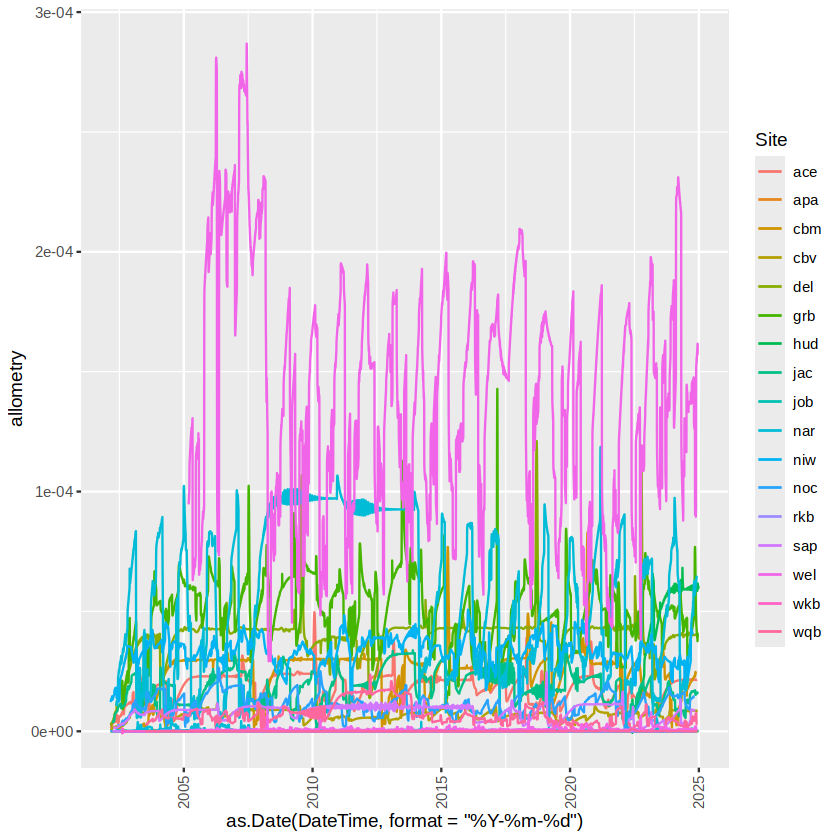

In [7]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Prorocentrales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site))+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

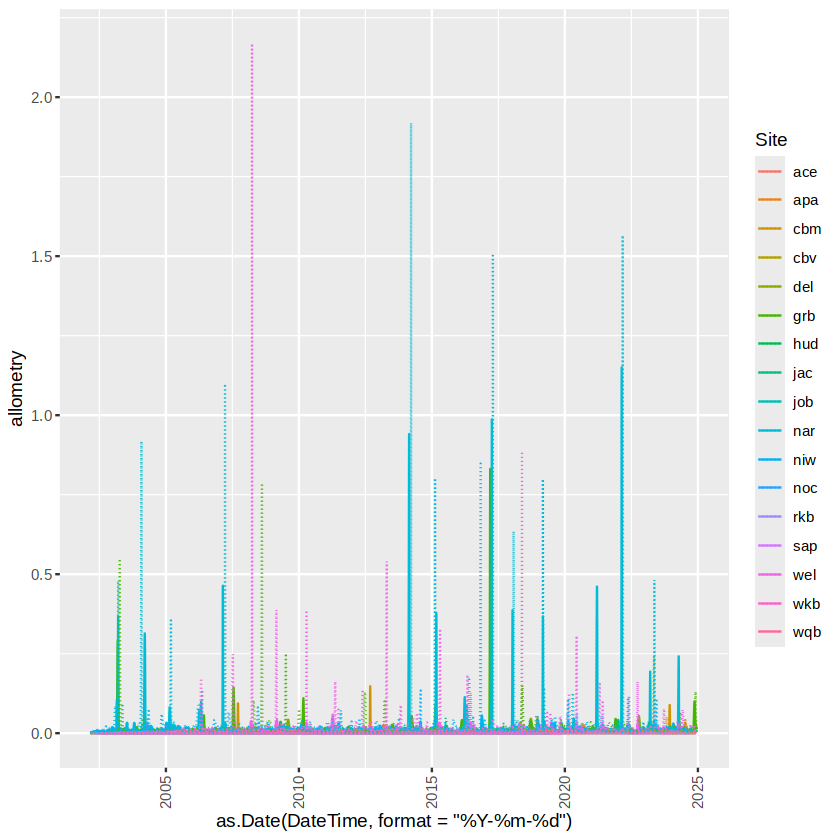

In [9]:
ggplot(nerrs_merged %>% dplyr::filter(taxon=="Isochrysidales")) + 
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=allometry,color=Site))+
    geom_line(aes(x=as.Date(DateTime,format="%Y-%m-%d"),y=metaT,color=Site),linetype="dotted")+  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) 

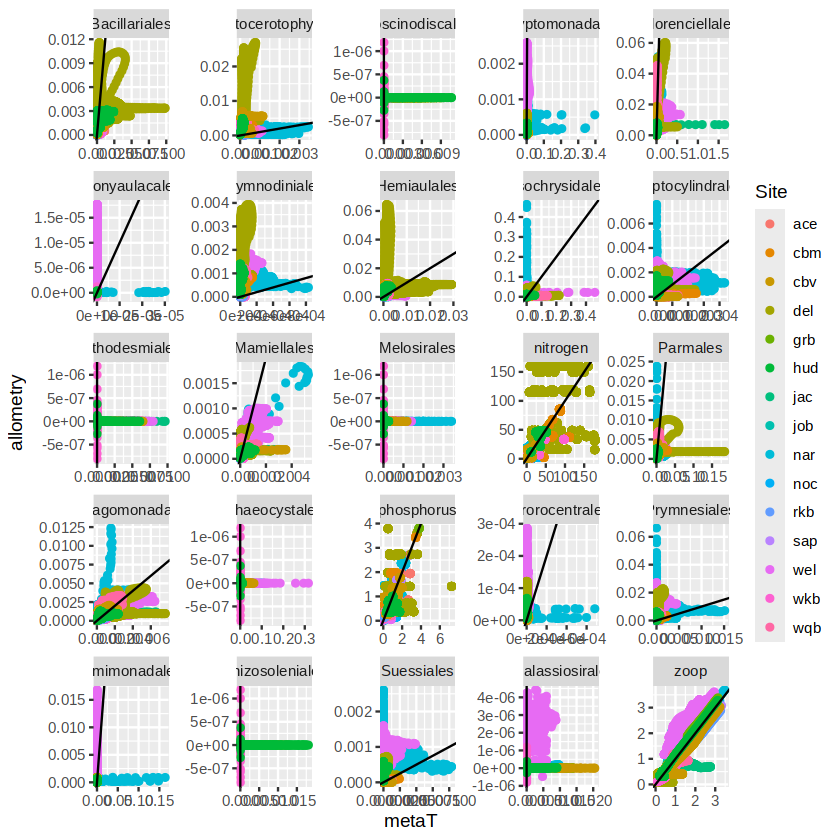

In [9]:
ggplot(nerrs_merged) + 
    geom_point(aes(x=metaT,y=allometry,color=Site))+
    geom_abline(aes(intercept=0,slope=1))+
    facet_wrap(~taxon,scales="free")

In [13]:
unique(nerrs_merged$Site)

[1] "ace" "wqb" "hud" "cbv" "wel" "noc" "cbm" "nar" "niw" "job" "jac" "rkb"
[13] "apa" "grb" "sap" "del" "wkb"